# 1. Title / Introduction

## Market Risk VaR & Expected Shortfall — EUR/USD

This project develops an illustrative market risk analysis framework for EUR/USD using historical market data.

The analysis evaluates downside risk using three approaches:

- Historical Value at Risk (VaR) and Expected Shortfall (ES)
- Parametric VaR and ES
- Monte Carlo VaR and ES

The project also includes stress testing, multi-horizon risk analysis, and translation of percentage-based risk measures into illustrative EUR portfolio losses.

The objective is to demonstrate the practical application of market risk concepts through Python-based quantitative analysis and to compare how different risk methodologies behave under different assumptions.

> **Scope:** This is an illustrative market risk analytics project for learning and portfolio demonstration. It is not intended to represent a complete regulatory capital or FRTB implementation.

### Project Objective

The primary objective is to estimate and interpret EUR/USD downside risk across different methodologies and risk horizons.

The analysis considers:

- **Confidence levels:** 95% and 99%
- **Risk horizons:** 1-day, 10-day, 21-day, and 252-day
- **Risk measures:** VaR and Expected Shortfall
- **Stress scenarios:** Historical and hypothetical downside shocks
- **Illustrative portfolio currency:** EUR (€)

The results are presented from both a quantitative and business perspective, linking percentage-based risk measures to hypothetical portfolio losses.

## 2. Imports

The analysis uses Python libraries for data manipulation, numerical calculations, visualization, market-data retrieval, and percentage formatting.

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

from matplotlib.ticker import PercentFormatter

In [40]:
data = yf.download(
    "EURUSD=X",
    period="5y",
    auto_adjust=False,
    progress=False
)

## 3. EUR/USD Data Collection

Daily EUR/USD exchange-rate data is obtained from Yahoo Finance using the `yfinance` Python library.

A five-year historical sample is used for the analysis. The closing exchange rate is used to calculate daily and multi-day EUR/USD returns.

The analysis uses EUR as the reporting and portfolio currency throughout the project.

The data is used for educational and portfolio-demonstration purposes and is not intended to represent production-grade market data.

In [41]:
# Extract the EUR/USD closing price series

close = data["Close"].squeeze()
close.name = "EUR/USD"

print(f"Observations: {len(close)}")
print(f"Start Date: {close.index.min().date()}")
print(f"End Date: {close.index.max().date()}")

Observations: 1300
Start Date: 2021-10-18
End Date: 2026-10-16


In [42]:
# Check the downloaded EUR/USD closing-price data

display(close.head())
display(close.tail())

,EUR/USD
Date,
2021-10-18,1.159703
2021-10-19,1.161386
2021-10-20,1.163196
2021-10-21,1.165501
2021-10-22,1.162534


,EUR/USD
Date,
2026-10-12,1.120473
2026-10-13,1.116022
2026-10-14,1.120448
2026-10-15,1.119507
2026-10-16,1.125239


## 4. Exploratory Analysis

The exploratory analysis examines the historical behavior of EUR/USD before calculating return-based risk measures.

The analysis includes:

- Historical EUR/USD price movement
- Daily return distribution
- Basic visual inspection of potential extreme movements

This step provides context for the subsequent VaR and Expected Shortfall calculations.

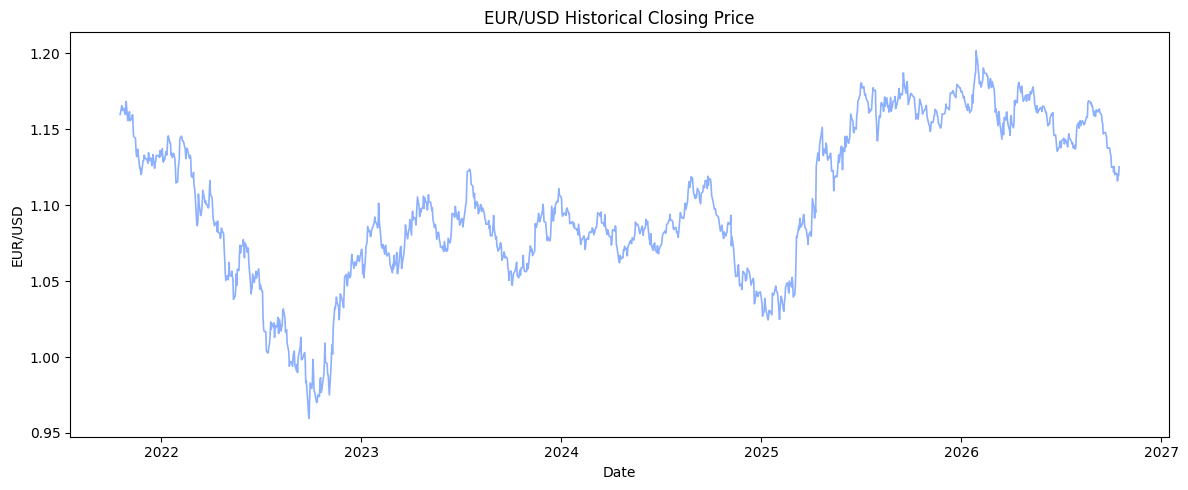

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(
    close.index,
    close.values,
    linewidth=1.2,
    color=plt.cm.coolwarm(0.25)
)

plt.title("EUR/USD Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("EUR/USD")

plt.tight_layout()
plt.show()

In [44]:
# Calculate daily EUR/USD returns

returns = close.pct_change().dropna()

print(f"Number of daily returns: {len(returns)}")

Number of daily returns: 1299


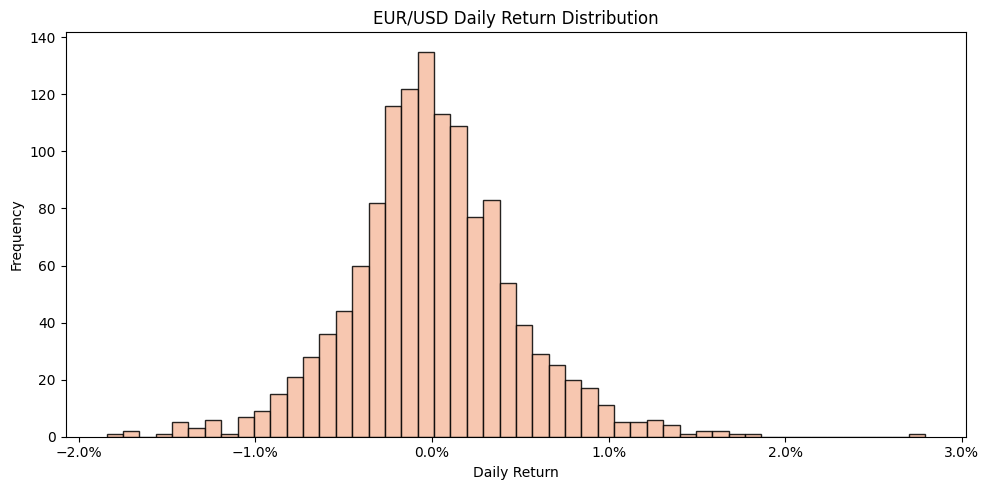

In [45]:
plt.figure(figsize=(10, 5))

plt.hist(
    returns,
    bins=50,
    color=plt.cm.coolwarm(0.65),
    edgecolor="black",
    alpha=0.85
)

plt.title("EUR/USD Daily Return Distribution")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.gca().xaxis.set_major_formatter(PercentFormatter(1))

plt.tight_layout()
plt.show()

### Exploratory Analysis — Key Observation

The EUR/USD closing price series shows the historical movement of the exchange rate over the five-year sample. The daily return distribution is approximately centered around zero, with observations concentrated around relatively small daily movements and a smaller number of larger positive and negative returns.

These extreme observations are particularly relevant for market risk measurement because VaR and Expected Shortfall focus on the lower tail of the return distribution.

## 5. Return Statistics

This section summarizes the statistical properties of daily EUR/USD returns used in the subsequent market risk analysis.

The key statistics include:

- Number of observations
- Mean daily return
- Daily volatility
- Minimum and maximum observed returns
- 25th, 50th, and 75th percentiles

In [46]:
# Calculate descriptive statistics for daily EUR/USD returns

return_statistics = pd.DataFrame({
    "Observations": [returns.count()],
    "Mean": [returns.mean()],
    "Volatility": [returns.std()],
    "Minimum": [returns.min()],
    "25th Percentile": [returns.quantile(0.25)],
    "Median": [returns.median()],
    "75th Percentile": [returns.quantile(0.75)],
    "Maximum": [returns.max()]
}).T

return_statistics.columns = ["Value"]

return_statistics

,Value
Observations,1299.000000
Mean,-0.000012
Volatility,0.004749
Minimum,-0.018418
25th Percentile,-0.002615
Median,-0.000197
75th Percentile,0.002666
Maximum,0.027919


In [47]:
# Format return statistics for presentation

return_statistics.style.format({
    "Value": lambda x: f"{x:,.0f}" if abs(x) > 1 else f"{x:.4%}"
})

,Value
Observations,"1,299"
Mean,-0.0012%
Volatility,0.4749%
Minimum,-1.8418%
25th Percentile,-0.2615%
Median,-0.0197%
75th Percentile,0.2666%
Maximum,2.7919%


### Return Statistics — Key Findings

Daily EUR/USD returns have a mean close to zero, while daily volatility remains relatively small compared with the larger tail movements observed in the sample. The return distribution contains both positive and negative tail observations, which are important for downside risk measurement.

These return characteristics provide the foundation for the subsequent VaR and Expected Shortfall calculations, which focus specifically on the downside tail of the return distribution.

## 6. Historical Value at Risk (VaR)

Historical VaR estimates the potential downside return at a specified confidence level using the empirical distribution of historical EUR/USD returns.

This analysis uses 95% and 99% confidence levels. A 99% Historical VaR represents the return threshold that is exceeded on the downside in approximately 1% of historical observations.

The estimates are expressed as negative returns because the analysis focuses on downside risk.

In [48]:
# Calculate Historical VaR

def historical_var(returns, confidence_level):
    return returns.quantile(1 - confidence_level)


var_95 = historical_var(returns, 0.95)
var_99 = historical_var(returns, 0.99)

print(f"95% Historical VaR: {var_95:.2%}")
print(f"99% Historical VaR: {var_99:.2%}")

95% Historical VaR: -0.74%
99% Historical VaR: -1.23%


In [49]:
# Create Historical VaR summary table

historical_var_summary = pd.DataFrame({
    "95%": [var_95],
    "99%": [var_99]
}, index=["VaR"])

historical_var_summary.style.format("{:.2%}")

,95%,99%
VaR,-0.74%,-1.23%


### Historical VaR — Key Findings

Historical VaR becomes more conservative as the confidence level increases because the calculation moves further into the lower tail of the empirical EUR/USD return distribution.

The 95% and 99% estimates therefore provide two different views of downside threshold risk, with the higher confidence level focusing on more extreme historical observations.

The estimates are data-dependent and will update automatically when the underlying EUR/USD sample changes.

## 7. Historical Expected Shortfall (ES)

Historical Expected Shortfall (ES) measures the average return in the tail beyond the Historical VaR threshold.

While VaR identifies a downside threshold at a selected confidence level, ES provides information about the average severity of observations that exceed that threshold.

This analysis calculates Historical ES at the 95% and 99% confidence levels using the empirical distribution of daily EUR/USD returns.

In [50]:
# Calculate Historical Expected Shortfall

def historical_es(returns, var):
    return returns[returns <= var].mean()


es_95 = historical_es(returns, var_95)
es_99 = historical_es(returns, var_99)

print(f"95% Historical ES: {es_95:.2%}")
print(f"99% Historical ES: {es_99:.2%}")

95% Historical ES: -1.03%
99% Historical ES: -1.47%


In [51]:
# Create Historical ES summary table

historical_es_summary = pd.DataFrame({
    "95%": [es_95],
    "99%": [es_99]
}, index=["Expected Shortfall"])

historical_es_summary.style.format("{:.2%}")

,95%,99%
Expected Shortfall,-1.03%,-1.47%


### Historical ES — Key Findings

Expected Shortfall is more negative than VaR at both confidence levels because it measures the average severity of historical returns beyond the corresponding VaR threshold.

The 99% ES therefore focuses on the average downside return within the most extreme portion of the historical daily EUR/USD return distribution.

These estimates are data-dependent and will update automatically when the underlying EUR/USD sample changes.

## 8. Parametric VaR & Expected Shortfall

Parametric VaR estimates downside risk using the historical mean and volatility of EUR/USD returns together with a distributional assumption.

This analysis assumes that daily returns are normally distributed.

Parametric VaR is calculated at the 95% and 99% confidence levels. Parametric Expected Shortfall is then estimated from the same normal-distribution assumption.

The results are compared with the Historical approach in the following section.

In [52]:
# Calculate inputs for Parametric VaR and Expected Shortfall

mean_return = returns.mean()
std_return = returns.std()

z_95 = -1.645
z_99 = -2.326

print(f"Mean Daily Return: {mean_return:.4%}")
print(f"Daily Volatility: {std_return:.4%}")
print(f"95% Z-score: {z_95}")
print(f"99% Z-score: {z_99}")

Mean Daily Return: -0.0012%
Daily Volatility: 0.4749%
95% Z-score: -1.645
99% Z-score: -2.326


In [53]:
# Calculate Parametric VaR

parametric_var_95 = mean_return + z_95 * std_return
parametric_var_99 = mean_return + z_99 * std_return

print(f"95% Parametric VaR: {parametric_var_95:.2%}")
print(f"99% Parametric VaR: {parametric_var_99:.2%}")

95% Parametric VaR: -0.78%
99% Parametric VaR: -1.11%


In [54]:
# Calculate Parametric Expected Shortfall

parametric_es_95 = (
    mean_return
    - std_return * np.exp(-0.5 * z_95**2)
    / (1 - 0.95)
    / np.sqrt(2 * np.pi)
)

parametric_es_99 = (
    mean_return
    - std_return * np.exp(-0.5 * z_99**2)
    / (1 - 0.99)
    / np.sqrt(2 * np.pi)
)

print(f"95% Parametric ES: {parametric_es_95:.2%}")
print(f"99% Parametric ES: {parametric_es_99:.2%}")

95% Parametric ES: -0.98%
99% Parametric ES: -1.27%


In [55]:
# Create Parametric VaR and ES summary table

parametric_summary = pd.DataFrame({
    "95%": [parametric_var_95, parametric_es_95],
    "99%": [parametric_var_99, parametric_es_99]
}, index=["VaR", "Expected Shortfall"])

parametric_summary.style.format("{:.2%}")

,95%,99%
VaR,-0.78%,-1.11%
Expected Shortfall,-0.98%,-1.27%


### Parametric VaR & ES — Key Findings

The Parametric approach provides model-based VaR and Expected Shortfall estimates using the historical mean and volatility under a normal-distribution assumption.

Expected Shortfall is more negative than VaR because it measures the average loss beyond the VaR threshold.

The results provide a model-based benchmark against which the Historical estimates can be compared, while remaining sensitive to changes in the underlying return statistics.

Parametric VaR estimates market risk by assuming that returns follow a specified probability distribution. In this case, we use the normal distribution and estimate VaR from the mean and standard deviation of historical EUR/USD returns.

## 9. Historical vs Parametric Comparison

This section compares Historical and Parametric estimates of Value at Risk (VaR) and Expected Shortfall (ES) at the 95% and 99% confidence levels.

The Historical approach uses the empirical EUR/USD return distribution, while the Parametric approach assumes normally distributed returns based on the historical mean and volatility.

Comparing the two approaches highlights the effect of distributional assumptions on estimated downside risk.

In [56]:
# Create a consolidated Historical vs Parametric risk summary

historical_parametric_summary = pd.DataFrame({
    "95%": [
        var_95,
        es_95,
        parametric_var_95,
        parametric_es_95
    ],
    "99%": [
        var_99,
        es_99,
        parametric_var_99,
        parametric_es_99
    ]
}, index=[
    "Historical VaR",
    "Historical Expected Shortfall",
    "Parametric VaR",
    "Parametric Expected Shortfall"
])

historical_parametric_summary.style.format("{:.2%}")

,95%,99%
Historical VaR,-0.74%,-1.23%
Historical Expected Shortfall,-1.03%,-1.47%
Parametric VaR,-0.78%,-1.11%
Parametric Expected Shortfall,-0.98%,-1.27%


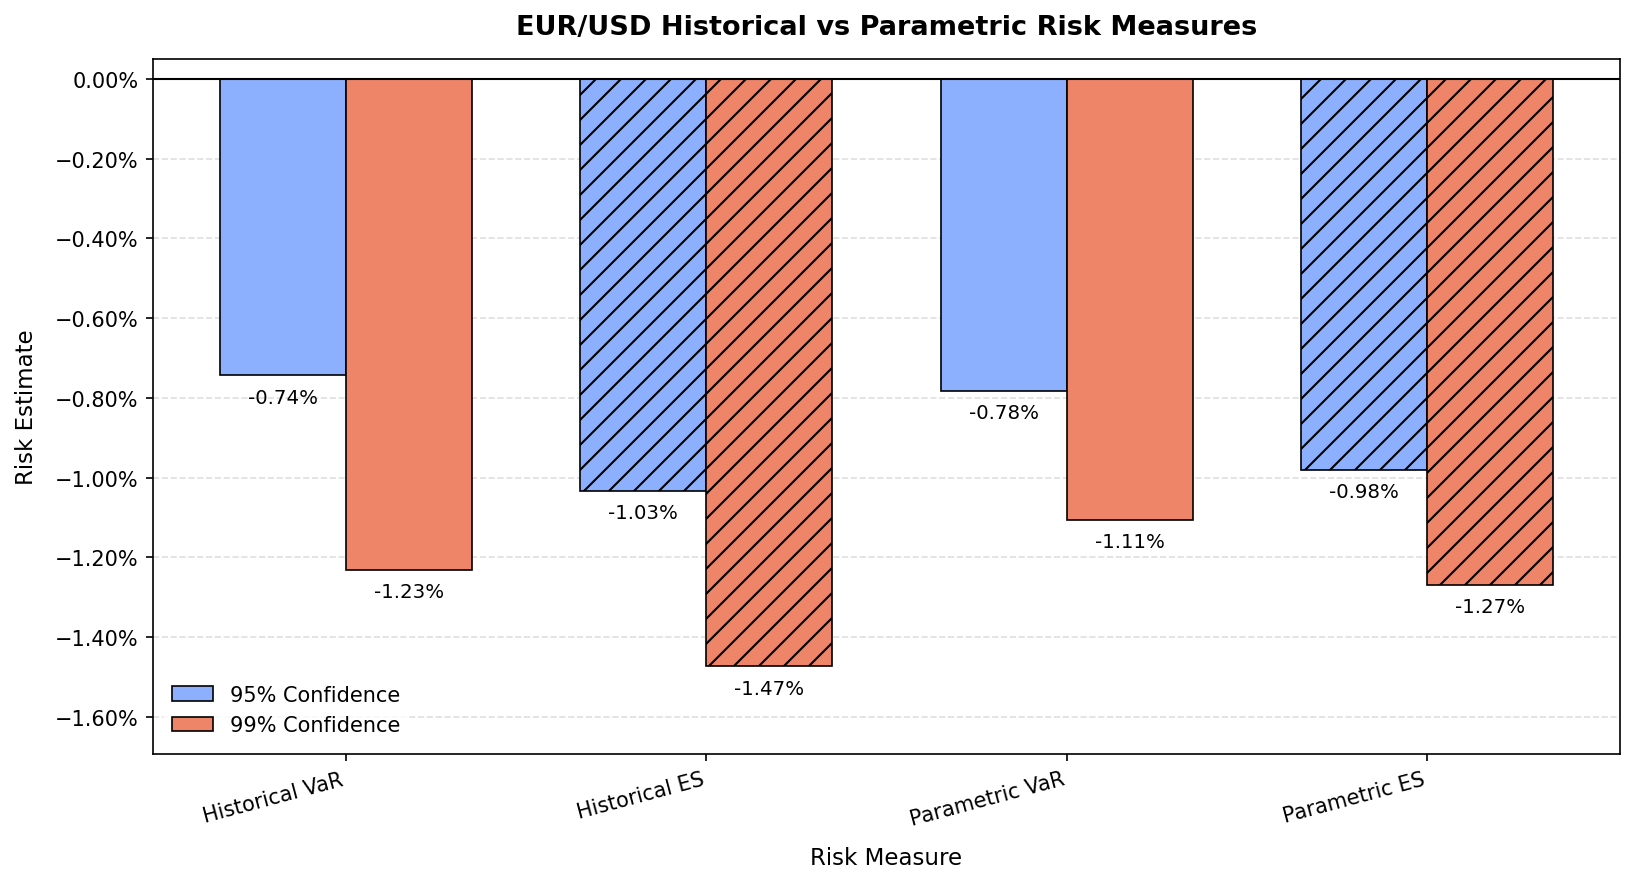

In [57]:
metrics = [
    "Historical VaR",
    "Historical ES",
    "Parametric VaR",
    "Parametric ES"
]

x = np.arange(len(metrics))
width = 0.35

values_95 = historical_parametric_summary["95%"].values
values_99 = historical_parametric_summary["99%"].values

fig, ax = plt.subplots(figsize=(11, 6), dpi=150)

# 1. Add subtle horizontal gridlines behind bars
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)

# 2. Draw bars with consistent edge styling
bars_95 = ax.bar(
    x - width / 2,
    values_95,
    width,
    label="95% Confidence",
    color=plt.cm.coolwarm(0.25),
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)

bars_99 = ax.bar(
    x + width / 2,
    values_99,
    width,
    label="99% Confidence",
    color=plt.cm.coolwarm(0.80),
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)

# 3. Apply diagonal hatches specifically to ES bars (indices 1 & 3)
for idx in [1, 3]:
    bars_95[idx].set_hatch("//")
    bars_99[idx].set_hatch("//")

# 4. Add percentage labels
for bars in [bars_95, bars_99]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2%}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, -6),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=9.5,
            fontweight="medium"
        )

# 5. Expand Y-limits to avoid bottom clipping
min_val = min(values_95.min(), values_99.min())
ax.set_ylim(min_val * 1.15, 0.0005)

ax.set_title("EUR/USD Historical vs Parametric Risk Measures", fontsize=13, pad=12, fontweight="bold")
ax.set_xlabel("Risk Measure", fontsize=11, labelpad=8)
ax.set_ylabel("Risk Estimate", fontsize=11, labelpad=8)
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=15, ha="right", fontsize=10)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.axhline(0, color="black", linewidth=1, zorder=4)
ax.legend(frameon=True, facecolor="white", edgecolor="none")

plt.tight_layout()
plt.show()

### Historical vs Parametric — Key Findings

At the 95% confidence level, the Historical and Parametric approaches produce broadly comparable risk estimates in this sample.

At the 99% confidence level, the Historical approach produces a more conservative tail-risk estimate than the Parametric approach.

The difference reflects the sensitivity of risk estimates to the underlying distributional assumptions: the Historical approach uses the observed empirical return distribution, while the Parametric approach assumes normally distributed returns.

Both sets of estimates will update automatically when the underlying EUR/USD data changes.

## 10. Monte Carlo VaR & Expected Shortfall

Monte Carlo simulation estimates market risk by generating a large number of hypothetical daily returns using the historical mean and volatility.

The simulation uses a normal distribution calibrated to the observed EUR/USD return characteristics. VaR is estimated from the simulated return distribution, while Expected Shortfall is calculated as the average simulated return beyond the VaR threshold.

This implementation represents a simplified Monte Carlo framework and does not incorporate volatility clustering, stochastic volatility, jumps, or other non-normal features of FX returns.

A fixed random seed is used to make the results reproducible.

In [58]:
n_simulations = 10_000

rng = np.random.default_rng(42)

simulated_returns = rng.normal(
    loc=mean_return,
    scale=std_return,
    size=n_simulations
)

print(f"Number of simulations: {n_simulations}")
print(f"Simulated Mean Return: {simulated_returns.mean():.4%}")
print(f"Simulated Volatility: {simulated_returns.std():.4%}")

Number of simulations: 10000
Simulated Mean Return: -0.0061%
Simulated Volatility: 0.4779%


In [59]:
mc_var_95 = np.quantile(simulated_returns, 1 - 0.95)
mc_var_99 = np.quantile(simulated_returns, 1 - 0.99)

print(f"95% Monte Carlo VaR: {mc_var_95:.2%}")
print(f"99% Monte Carlo VaR: {mc_var_99:.2%}")

95% Monte Carlo VaR: -0.80%
99% Monte Carlo VaR: -1.13%


In [60]:
mc_es_95 = simulated_returns[simulated_returns <= mc_var_95].mean()
mc_es_99 = simulated_returns[simulated_returns <= mc_var_99].mean()

print(f"95% Monte Carlo ES: {mc_es_95:.2%}")
print(f"99% Monte Carlo ES: {mc_es_99:.2%}")

95% Monte Carlo ES: -0.99%
99% Monte Carlo ES: -1.30%


In [61]:
monte_carlo_summary = pd.DataFrame({
    "95%": [mc_var_95, mc_es_95],
    "99%": [mc_var_99, mc_es_99]
}, index=[
    "VaR",
    "Expected Shortfall"
])

monte_carlo_summary.style.format("{:.2%}")

,95%,99%
VaR,-0.80%,-1.13%
Expected Shortfall,-0.99%,-1.30%


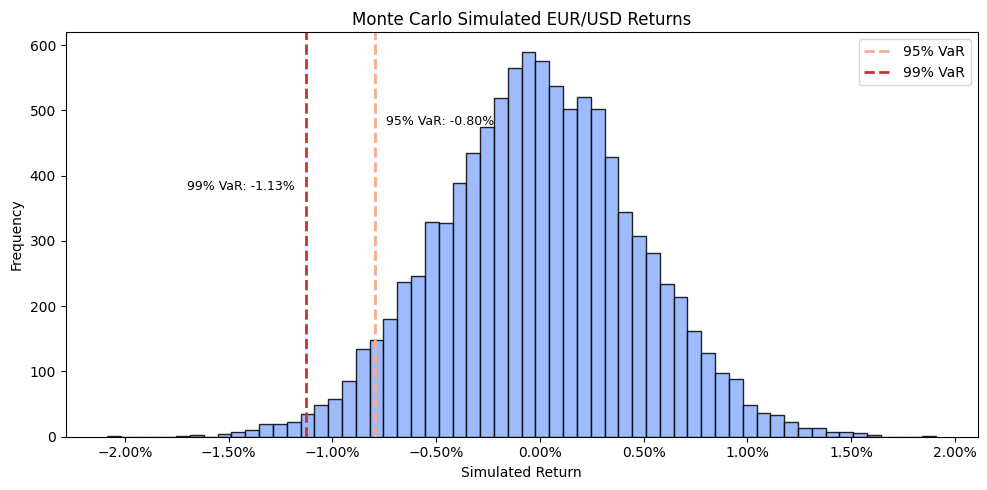

In [62]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    simulated_returns,
    bins=60,
    color=plt.cm.coolwarm(0.25),
    edgecolor="black",
    alpha=0.85
)

# VaR lines
ax.axvline(
    mc_var_95,
    color=plt.cm.coolwarm(0.70),
    linestyle="--",
    linewidth=2,
    label="95% VaR"
)

ax.axvline(
    mc_var_99,
    color=plt.cm.coolwarm(0.95),
    linestyle="--",
    linewidth=2,
    label="99% VaR"
)

# Get current y-axis limit for annotation positioning
y_max = ax.get_ylim()[1]

# 95% VaR label — placed to the right of the 95% VaR line
ax.annotate(
    f"95% VaR: {mc_var_95:.2%}",
    xy=(mc_var_95, y_max * 0.78),
    xytext=(8, 0),
    textcoords="offset points",
    ha="left",
    va="center",
    fontsize=9
)

# 99% VaR label — placed to the left of the 99% VaR line
ax.annotate(
    f"99% VaR: {mc_var_99:.2%}",
    xy=(mc_var_99, y_max * 0.62),
    xytext=(-8, 0),
    textcoords="offset points",
    ha="right",
    va="center",
    fontsize=9
)

ax.set_title("Monte Carlo Simulated EUR/USD Returns")
ax.set_xlabel("Simulated Return")
ax.set_ylabel("Frequency")

ax.xaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.legend(
    loc="upper right"
)

plt.tight_layout()
plt.show()

### Monte Carlo VaR & ES — Key Findings

The Monte Carlo estimates are broadly consistent with the Parametric results because both approaches use a normal distribution calibrated to the same historical mean and volatility.

The simulation provides a flexible framework for generating a large number of hypothetical market outcomes and estimating tail risk from the simulated distribution.

The results are dependent on the assumed probability distribution, historical calibration parameters, and number of simulations.

## 11. Historical vs Parametric vs Monte Carlo Comparison

This section compares the three risk estimation approaches using the same EUR/USD return sample and confidence levels.

Historical VaR and Expected Shortfall are based on the empirical return distribution, while Parametric and Monte Carlo approaches rely on a normal distribution calibrated to the historical mean and volatility.

The comparison highlights how distributional assumptions affect estimated tail risk.

In [63]:
all_methods_summary = pd.DataFrame({
    "95%": [
        var_95,
        es_95,
        parametric_var_95,
        parametric_es_95,
        mc_var_95,
        mc_es_95
    ],
    "99%": [
        var_99,
        es_99,
        parametric_var_99,
        parametric_es_99,
        mc_var_99,
        mc_es_99
    ]
}, index=[
    "Historical VaR",
    "Historical Expected Shortfall",
    "Parametric VaR",
    "Parametric Expected Shortfall",
    "Monte Carlo VaR",
    "Monte Carlo Expected Shortfall"
])

all_methods_summary.style.format("{:.2%}")

,95%,99%
Historical VaR,-0.74%,-1.23%
Historical Expected Shortfall,-1.03%,-1.47%
Parametric VaR,-0.78%,-1.11%
Parametric Expected Shortfall,-0.98%,-1.27%
Monte Carlo VaR,-0.80%,-1.13%
Monte Carlo Expected Shortfall,-0.99%,-1.30%


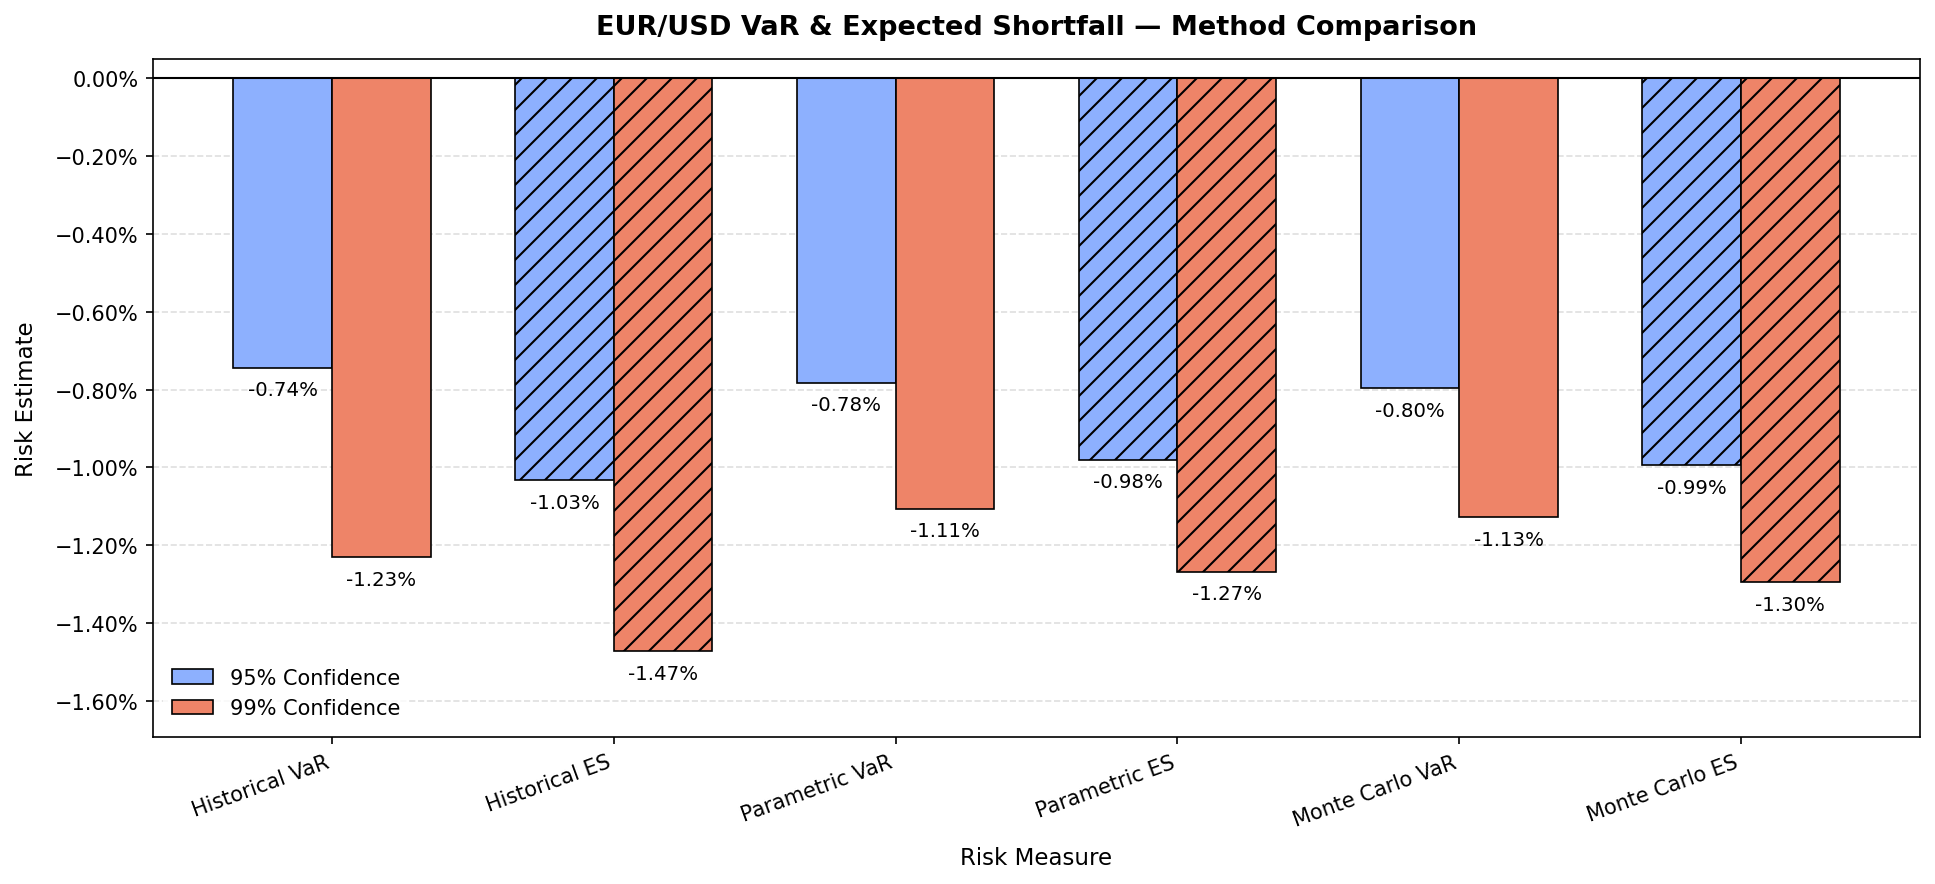

In [64]:
metrics = [
    "Historical VaR",
    "Historical ES",
    "Parametric VaR",
    "Parametric ES",
    "Monte Carlo VaR",
    "Monte Carlo ES"
]

values_95 = np.array([
    var_95,
    es_95,
    parametric_var_95,
    parametric_es_95,
    mc_var_95,
    mc_es_95
])

values_99 = np.array([
    var_99,
    es_99,
    parametric_var_99,
    parametric_es_99,
    mc_var_99,
    mc_es_99
])

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

# Subtle horizontal gridlines behind bars
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)

# Bars with clean uniform borders
bars_95 = ax.bar(
    x - width / 2,
    values_95,
    width,
    label="95% Confidence",
    color=plt.cm.coolwarm(0.25),
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)

bars_99 = ax.bar(
    x + width / 2,
    values_99,
    width,
    label="99% Confidence",
    color=plt.cm.coolwarm(0.80),
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)

# Apply diagonal hatches to all Expected Shortfall (ES) bars (indices 1, 3, 5)
es_indices = [1, 3, 5]
for idx in es_indices:
    bars_95[idx].set_hatch("//")
    bars_99[idx].set_hatch("//")

# Percentage labels with clean offset
for bars in [bars_95, bars_99]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2%}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, -6),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=9.5,
            fontweight="medium"
        )

# Y-axis padding so -1.47% does not clip against the bottom spine
min_val = min(values_95.min(), values_99.min())
ax.set_ylim(min_val * 1.15, 0.0005)

ax.set_title("EUR/USD VaR & Expected Shortfall — Method Comparison", fontsize=13, pad=12, fontweight="bold")
ax.set_xlabel("Risk Measure", fontsize=11, labelpad=8)
ax.set_ylabel("Risk Estimate", fontsize=11, labelpad=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=20, ha="right", fontsize=10)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.axhline(0, color="black", linewidth=1, zorder=4)
ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="none")

plt.tight_layout()
plt.show()

### Method Comparison — Key Findings

The three methodologies provide broadly comparable risk estimates at the 95% confidence level in this sample.

At the 99% confidence level, the Historical approach is more conservative than the Parametric and Monte Carlo approaches.

The Parametric and Monte Carlo results are closely aligned because the Monte Carlo simulation is calibrated using the same historical mean and volatility under a normal-distribution assumption.

The differences between Historical and normal-based approaches demonstrate the impact of distributional assumptions when estimating extreme tail risk. The reported values and charts will update automatically when the underlying EUR/USD sample changes.

## 12. Stress Testing

Stress testing evaluates the potential impact of severe but plausible adverse market movements.

This section considers the historical worst observed daily EUR/USD return together with hypothetical downside shocks of -1%, -2%, -3%, and -5%.

Unlike VaR and Expected Shortfall, stress testing does not rely on a specified confidence level. Instead, it examines the portfolio impact of explicitly defined adverse scenarios.

In [65]:
worst_daily_return = returns.min()

print(f"Historical Worst Daily Return: {worst_daily_return:.2%}")

Historical Worst Daily Return: -1.84%


In [66]:
stress_scenarios = {
    "Historical Worst Day": worst_daily_return,
    "-1% Shock": -0.01,
    "-2% Shock": -0.02,
    "-3% Shock": -0.03,
    "-5% Shock": -0.05
}

stress_summary = pd.DataFrame.from_dict(
    stress_scenarios,
    orient="index",
    columns=["Return Shock"]
)

stress_summary.style.format("{:.2%}")

,Return Shock
Historical Worst Day,-1.84%
-1% Shock,-1.00%
-2% Shock,-2.00%
-3% Shock,-3.00%
-5% Shock,-5.00%


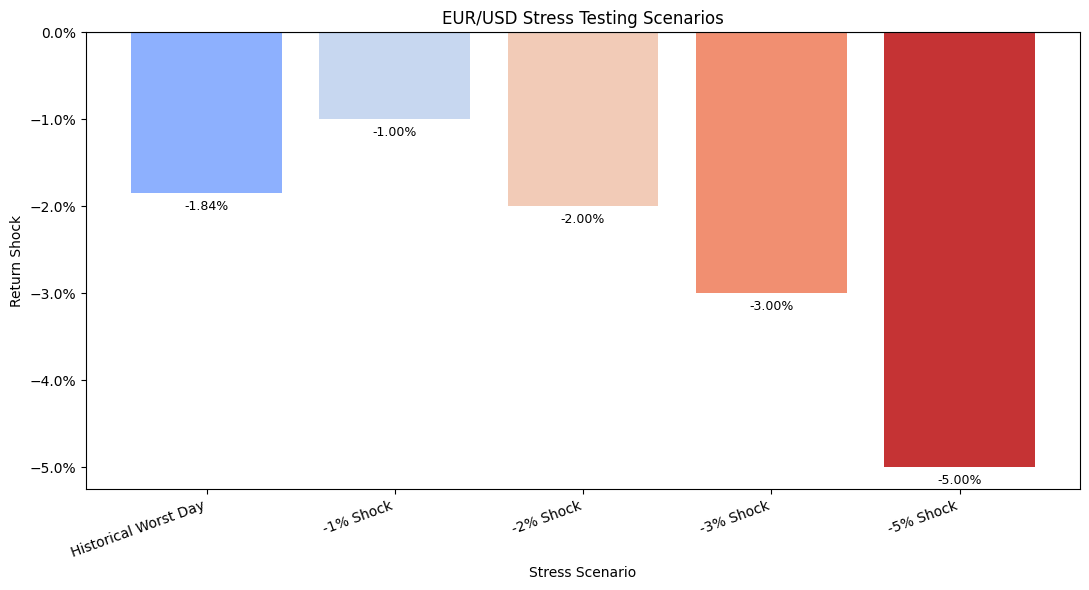

In [67]:
stress_scenarios = [
    "Historical Worst Day",
    "-1% Shock",
    "-2% Shock",
    "-3% Shock",
    "-5% Shock"
]

stress_values = [
    returns.min(),
    -0.01,
    -0.02,
    -0.03,
    -0.05
]

x = np.arange(len(stress_scenarios))

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    x,
    stress_values,
    color=plt.cm.coolwarm(np.linspace(0.25, 0.95, len(stress_values)))
)

# Add percentage labels
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2%}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, -5),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=9
    )

ax.set_title("EUR/USD Stress Testing Scenarios")
ax.set_xlabel("Stress Scenario")
ax.set_ylabel("Return Shock")

ax.set_xticks(x)
ax.set_xticklabels(
    stress_scenarios,
    rotation=20,
    ha="right"
)

ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.axhline(0, linewidth=0.8)

plt.tight_layout()
plt.show()

### Stress Testing — Key Findings

The historical worst-day scenario represents the most severe observed daily downside return in the current sample.

The hypothetical scenarios extend beyond the historical worst-day observation to examine progressively more severe downside shocks. The most severe scenario is included as a hypothetical stress case rather than a forecast.

Stress testing complements VaR and Expected Shortfall by examining predefined extreme scenarios that may fall outside the assumptions or historical observations used by statistical risk models.

The historical worst-day result will update automatically when the underlying EUR/USD sample changes.

## 13. Stress Loss Analysis

To translate the percentage stress scenarios into monetary terms, the stress returns are applied to an illustrative €1 million EUR/USD notional.

The calculation provides a simple interpretation of the potential loss under each scenario.

This is an illustrative stress-loss calculation and should not be interpreted as a full portfolio valuation or regulatory capital calculation.

In [68]:
stress_notional = 1_000_000

stress_loss_summary = stress_summary.copy()

stress_loss_summary["Illustrative Loss (€)"] = (
    stress_loss_summary["Return Shock"].abs() * stress_notional
)

stress_loss_summary.style.format({
    "Return Shock": "{:.2%}",
    "Illustrative Loss (€)": "€{:,.0f}"
})

,Return Shock,Illustrative Loss (€)
Historical Worst Day,-1.84%,"€18,418"
-1% Shock,-1.00%,"€10,000"
-2% Shock,-2.00%,"€20,000"
-3% Shock,-3.00%,"€30,000"
-5% Shock,-5.00%,"€50,000"


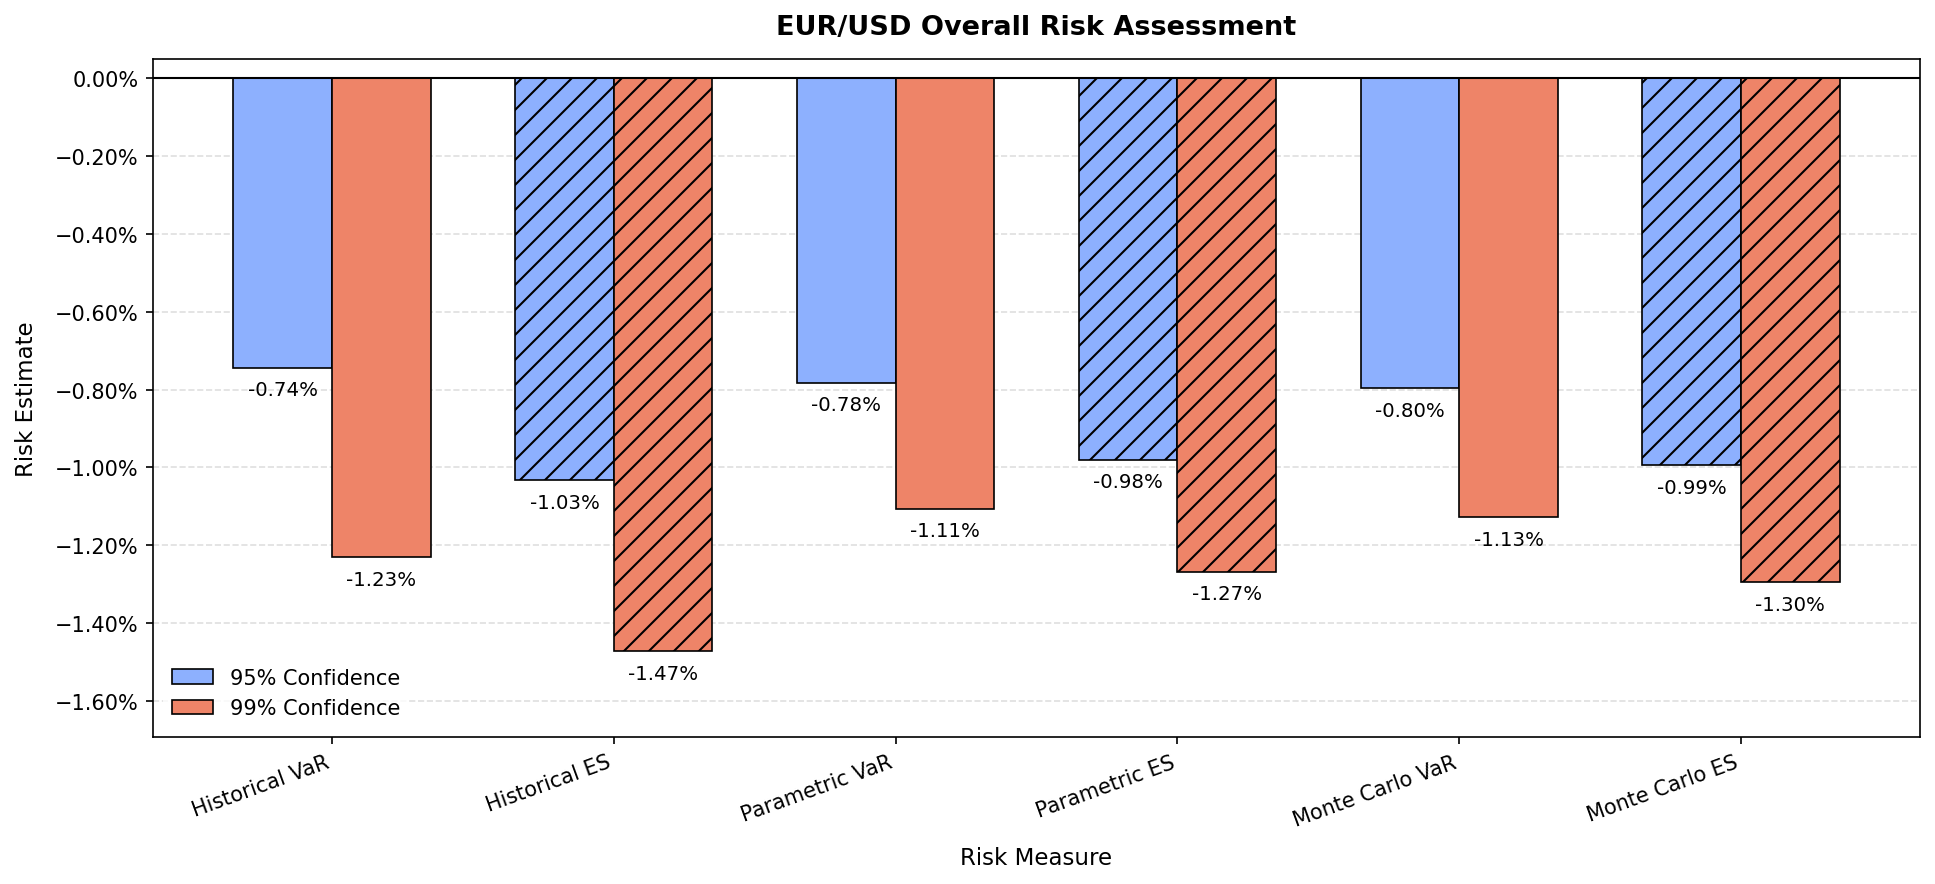

In [69]:
metrics = [
    "Historical VaR",
    "Historical ES",
    "Parametric VaR",
    "Parametric ES",
    "Monte Carlo VaR",
    "Monte Carlo ES"
]

values_95 = np.array([
    var_95,
    es_95,
    parametric_var_95,
    parametric_es_95,
    mc_var_95,
    mc_es_95
])

values_99 = np.array([
    var_99,
    es_99,
    parametric_var_99,
    parametric_es_99,
    mc_var_99,
    mc_es_99
])

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

# Líneas de cuadrícula sutiles detrás de las barras
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)

# Barras con bordes uniformes y definidos
bars_95 = ax.bar(
    x - width / 2,
    values_95,
    width,
    label="95% Confidence",
    color=plt.cm.coolwarm(0.25),
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)

bars_99 = ax.bar(
    x + width / 2,
    values_99,
    width,
    label="99% Confidence",
    color=plt.cm.coolwarm(0.80),
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)

# Aplicar las líneas diagonales a las barras de Expected Shortfall (índices 1, 3 y 5)
es_indices = [1, 3, 5]
for idx in es_indices:
    bars_95[idx].set_hatch("//")
    bars_99[idx].set_hatch("//")

# Etiquetas de porcentaje con espaciado adecuado
for bars in [bars_95, bars_99]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2%}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, -6),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=9.5,
            fontweight="medium"
        )

# Margen en el eje Y para evitar que el texto toque el marco inferior
min_val = min(values_95.min(), values_99.min())
ax.set_ylim(min_val * 1.15, 0.0005)

ax.set_title("EUR/USD Overall Risk Assessment", fontsize=13, pad=12, fontweight="bold")
ax.set_xlabel("Risk Measure", fontsize=11, labelpad=8)
ax.set_ylabel("Risk Estimate", fontsize=11, labelpad=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=20, ha="right", fontsize=10)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.axhline(0, color="black", linewidth=1, zorder=4)
ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="none")

plt.tight_layout()
plt.show()

### Stress Loss Analysis — Key Findings

For the illustrative EUR/USD notional, the stress scenarios translate percentage return shocks into corresponding hypothetical EUR losses.

Losses increase as the magnitude of the downside shock increases, with the most severe hypothetical scenario producing the largest estimated loss.

The historical worst-day loss is based on the most severe observed daily return in the current sample, while the hypothetical scenarios represent predefined adverse shocks.

These monetary figures are illustrative translations of percentage-based stress scenarios applied to a hypothetical notional and should not be interpreted as a full portfolio risk calculation.

## 14. Overall Risk Assessment

The overall risk assessment consolidates the VaR and Expected Shortfall estimates obtained from the Historical, Parametric, and Monte Carlo approaches.

The comparison is presented at both the 95% and 99% confidence levels to provide a consistent view of EUR/USD downside risk.

In [70]:
overall_risk_summary = pd.DataFrame({
    "95%": [
        var_95,
        es_95,
        parametric_var_95,
        parametric_es_95,
        mc_var_95,
        mc_es_95
    ],
    "99%": [
        var_99,
        es_99,
        parametric_var_99,
        parametric_es_99,
        mc_var_99,
        mc_es_99
    ]
}, index=[
    "Historical VaR",
    "Historical Expected Shortfall",
    "Parametric VaR",
    "Parametric Expected Shortfall",
    "Monte Carlo VaR",
    "Monte Carlo Expected Shortfall"
])

overall_risk_summary.style.format("{:.2%}")

,95%,99%
Historical VaR,-0.74%,-1.23%
Historical Expected Shortfall,-1.03%,-1.47%
Parametric VaR,-0.78%,-1.11%
Parametric Expected Shortfall,-0.98%,-1.27%
Monte Carlo VaR,-0.80%,-1.13%
Monte Carlo Expected Shortfall,-0.99%,-1.30%


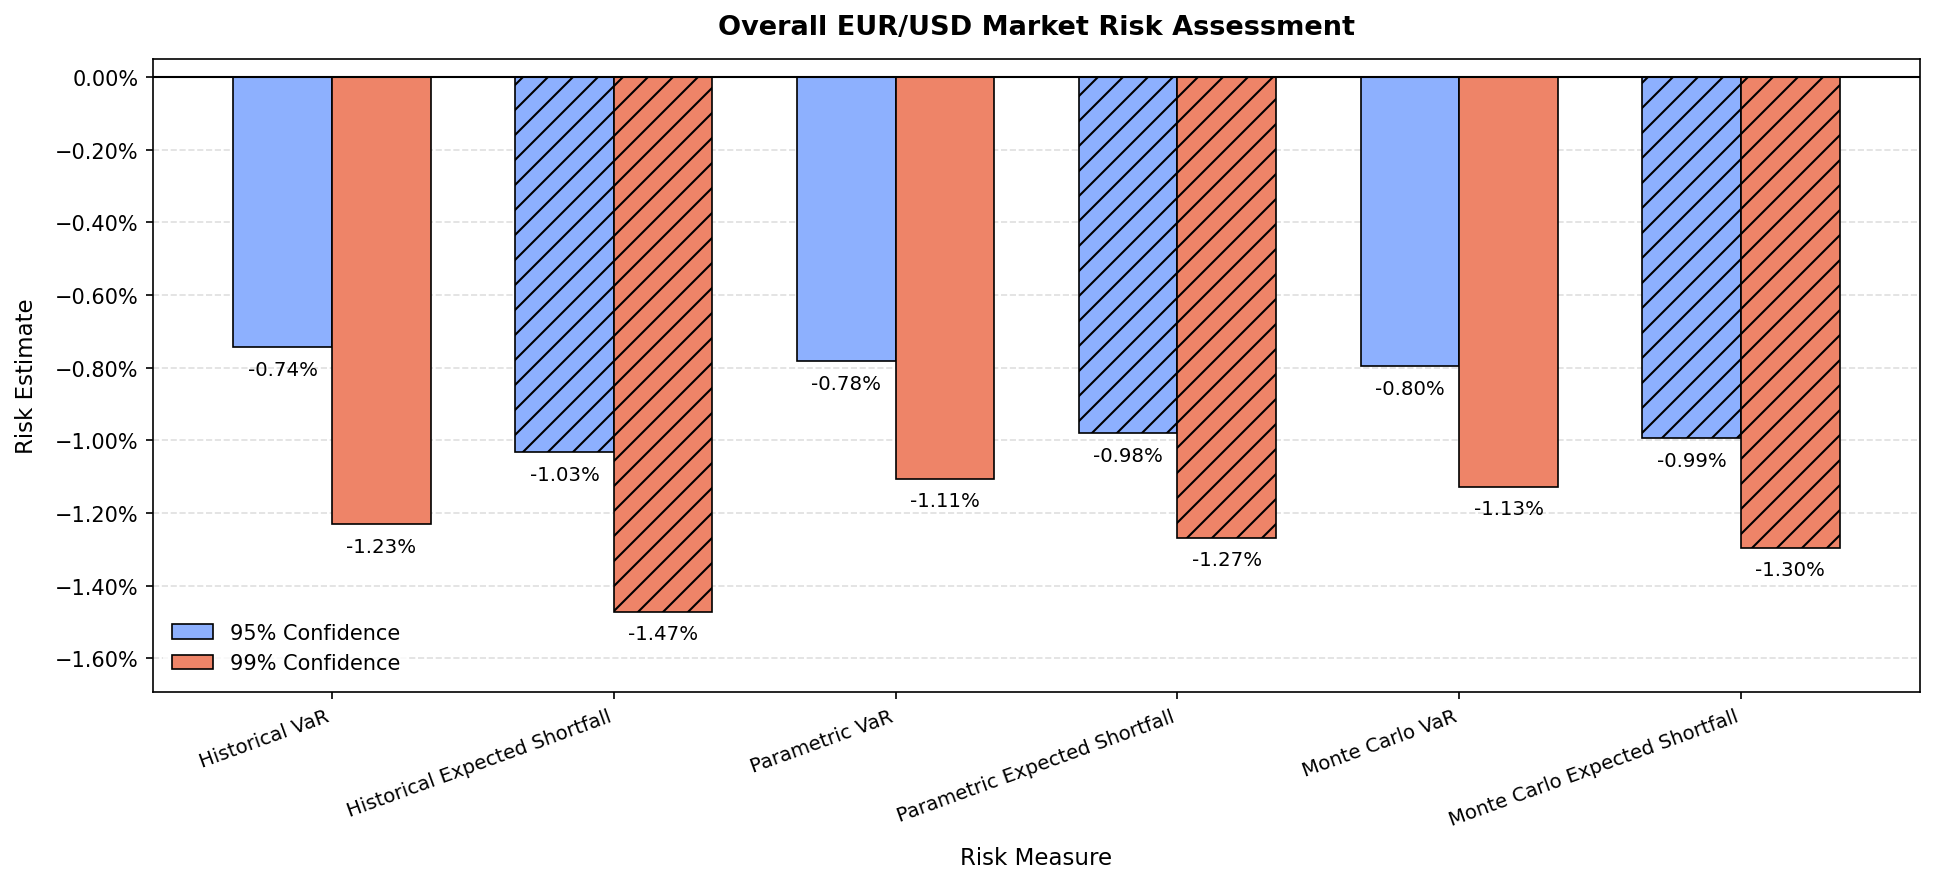

In [71]:
metrics = [
    "Historical VaR",
    "Historical Expected Shortfall",
    "Parametric VaR",
    "Parametric Expected Shortfall",
    "Monte Carlo VaR",
    "Monte Carlo Expected Shortfall"
]

values_95 = np.array([
    var_95,
    es_95,
    parametric_var_95,
    parametric_es_95,
    mc_var_95,
    mc_es_95
])

values_99 = np.array([
    var_99,
    es_99,
    parametric_var_99,
    parametric_es_99,
    mc_var_99,
    mc_es_99
])

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

# Líneas de cuadrícula sutiles detrás de las barras
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)

# Barras con bordes uniformes
bars_95 = ax.bar(
    x - width / 2,
    values_95,
    width,
    label="95% Confidence",
    color=plt.cm.coolwarm(0.25),
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)

bars_99 = ax.bar(
    x + width / 2,
    values_99,
    width,
    label="99% Confidence",
    color=plt.cm.coolwarm(0.80),
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)

# Aplicar las líneas diagonales a las barras de Expected Shortfall (índices 1, 3 y 5)
es_indices = [1, 3, 5]
for idx in es_indices:
    bars_95[idx].set_hatch("//")
    bars_99[idx].set_hatch("//")

# Etiquetas de porcentaje con espaciado adecuado
for bars in [bars_95, bars_99]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2%}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, -6),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=9.5,
            fontweight="medium"
        )

# Margen en el eje Y para que los textos inferiores tengan suficiente espacio
min_val = min(values_95.min(), values_99.min())
ax.set_ylim(min_val * 1.15, 0.0005)

ax.set_title("Overall EUR/USD Market Risk Assessment", fontsize=13, pad=12, fontweight="bold")
ax.set_xlabel("Risk Measure", fontsize=11, labelpad=8)
ax.set_ylabel("Risk Estimate", fontsize=11, labelpad=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=20, ha="right", fontsize=9.5)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.axhline(0, color="black", linewidth=1, zorder=4)
ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="none")

plt.tight_layout()
plt.show()

### Overall Risk Assessment — Key Findings

The three methodologies produce broadly comparable estimates at the 95% confidence level in this sample.

At the 99% confidence level, the Historical approach produces the most conservative tail-risk estimates among the three methods.

The Parametric and Monte Carlo estimates are closely aligned because both approaches are based on the same normal-distribution assumption calibrated to the historical mean and volatility.

Expected Shortfall is more negative than VaR across all methodologies because it measures the average loss beyond the VaR threshold.

The numerical estimates shown in the table and chart are generated from the current EUR/USD dataset and will update automatically when the notebook is rerun.

## 15. Risk Conclusions

The analysis provides a comparative assessment of EUR/USD downside risk using Historical, Parametric, and Monte Carlo approaches.

At the 95% confidence level, the three methodologies produce broadly similar VaR and Expected Shortfall estimates in this sample. At the 99% confidence level, the Historical approach produces the most conservative tail-risk estimates.

The Parametric and Monte Carlo approaches produce closely aligned results because the Monte Carlo simulation is based on a normal distribution calibrated using the historical mean and volatility. The difference between the Historical estimates and the normal-based approaches highlights the sensitivity of risk estimates to the underlying methodology and distributional assumptions.

Stress testing provides an additional perspective by examining severe hypothetical market shocks. The hypothetical stress scenarios translate percentage shocks into illustrative EUR losses for a €1 million notional.

Overall, the case study demonstrates how VaR, Expected Shortfall, Monte Carlo simulation, and stress testing can be used together to assess market risk from different perspectives.

The results are illustrative and depend on the historical sample, model assumptions, simulation methodology, and hypothetical notional used in the analysis. They should not be interpreted as a full portfolio risk calculation or as regulatory capital requirements. Numerical outputs are generated from the current dataset and update when the notebook is rerun.

## 16. VaR Across Risk Horizons

This section examines how historical EUR/USD downside risk changes across different holding periods: 1 day, 10 days, 21 days, and 252 days.

The 1-day horizon represents short-term market risk, while the 10-day horizon provides a useful longer-horizon risk perspective. The 21-day and 252-day horizons provide illustrative monthly and annual perspectives.

These horizons are analytical examples and should not be interpreted as equivalent to specific regulatory capital requirements.

### Risk Horizon Methodology

Historical multi-day returns are calculated directly from EUR/USD closing prices using the percentage change over each specified horizon.

Historical VaR is calculated from the lower tail of the resulting multi-day return distribution, while Expected Shortfall represents the average return beyond the VaR threshold.

The analysis uses 1-day, 10-day, 21-day, and 252-day horizons to illustrate how observed historical risk changes with the holding period.

The multi-day historical approach uses observed overlapping returns over each horizon and therefore represents an empirical historical-risk analysis rather than a full portfolio revaluation framework.

In [72]:
horizons = {
    "1-Day": 1,
    "10-Day": 10,
    "21-Day": 21,
    "252-Day": 252
}

horizon_returns = {}

for horizon_name, days in horizons.items():
    horizon_returns[horizon_name] = close.pct_change(days).dropna()

for horizon_name, horizon_return in horizon_returns.items():
    print(f"{horizon_name}: {len(horizon_return)} observations")

1-Day: 1299 observations
10-Day: 1290 observations
21-Day: 1279 observations
252-Day: 1048 observations


### Historical VaR & Expected Shortfall by Horizon

Historical VaR and Expected Shortfall are calculated at the 99% confidence level for each holding period.

The estimates are based on the empirical distribution of observed multi-day EUR/USD returns.

In [73]:
horizon_risk = []

for horizon_name, horizon_return in horizon_returns.items():
    horizon_var = horizon_return.quantile(0.01)
    horizon_es = horizon_return[horizon_return <= horizon_var].mean()

    horizon_risk.append({
        "Horizon": horizon_name,
        "VaR": horizon_var,
        "Expected Shortfall": horizon_es
    })

horizon_risk_summary = pd.DataFrame(horizon_risk)

horizon_risk_summary = horizon_risk_summary.set_index("Horizon")

horizon_risk_summary.style.format("{:.2%}")

,VaR,Expected Shortfall
Horizon,,
1-Day,-1.23%,-1.47%
10-Day,-3.33%,-4.08%
21-Day,-4.24%,-4.82%
252-Day,-14.90%,-16.00%


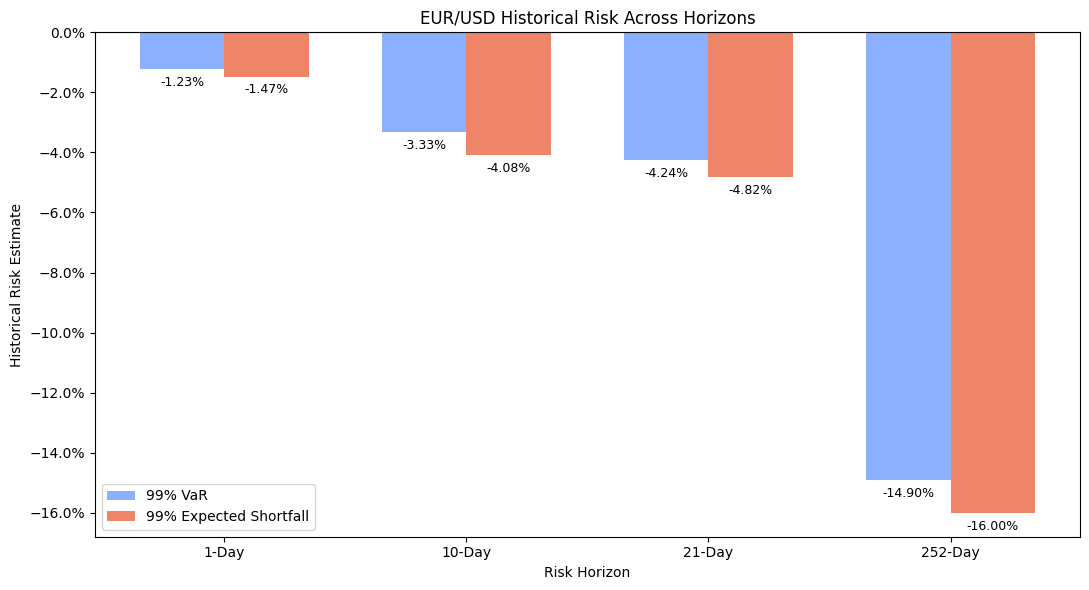

In [74]:
horizon_names = list(horizons.keys())

var_values = []
es_values = []

for horizon_name in horizon_names:
    horizon_data = horizon_returns[horizon_name]

    var = horizon_data.quantile(0.01)
    es = horizon_data[horizon_data <= var].mean()

    var_values.append(var)
    es_values.append(es)

x = np.arange(len(horizon_names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_var = ax.bar(
    x - width / 2,
    var_values,
    width,
    label="99% VaR",
    color=plt.cm.coolwarm(0.25)
)

bars_es = ax.bar(
    x + width / 2,
    es_values,
    width,
    label="99% Expected Shortfall",
    color=plt.cm.coolwarm(0.80)
)

# Add percentage labels
for bars in [bars_var, bars_es]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.2%}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, -5),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=9
        )

ax.set_title("EUR/USD Historical Risk Across Horizons")
ax.set_xlabel("Risk Horizon")
ax.set_ylabel("Historical Risk Estimate")

ax.set_xticks(x)
ax.set_xticklabels(horizon_names)

ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.axhline(0, linewidth=0.8)

ax.legend(loc="best")

plt.tight_layout()
plt.show()

### Horizon Comparison — Key Findings

Historical downside risk increases as the holding period becomes longer in the current sample.

At the 99% confidence level, both VaR and Expected Shortfall become more negative as the horizon extends, reflecting the cumulative effect of multi-day EUR/USD return movements.

Expected Shortfall is more negative than VaR at every horizon because it measures the average severity of losses beyond the VaR threshold.

The 252-day estimates represent the empirical distribution of observed 252-trading-day EUR/USD returns and should be interpreted as a long-horizon historical scenario rather than a regulatory VaR measure.

The numerical estimates and corresponding charts update automatically when the underlying EUR/USD data changes.

### Illustrative €10 Million Portfolio Loss Translation

To provide a business interpretation of the percentage-based historical risk estimates, the 99% VaR and Expected Shortfall estimates are translated into illustrative monetary losses for a hypothetical €10 million EUR/USD notional.

These figures are simplified translations of percentage return risk applied to a notional amount. They are not a full portfolio VaR calculation and should not be interpreted as regulatory capital requirements.

In [75]:
portfolio_notional = 10_000_000

portfolio_loss_summary = horizon_risk_summary.copy()

portfolio_loss_summary["VaR Loss (€)"] = (
    portfolio_loss_summary["VaR"].abs() * portfolio_notional
)

portfolio_loss_summary["Expected Shortfall Loss (€)"] = (
    portfolio_loss_summary["Expected Shortfall"].abs() * portfolio_notional
)

portfolio_loss_summary.style.format({
    "VaR": "{:.2%}",
    "Expected Shortfall": "{:.2%}",
    "VaR Loss (€)": "€{:,.0f}",
    "Expected Shortfall Loss (€)": "€{:,.0f}"
})

,VaR,Expected Shortfall,VaR Loss (€),Expected Shortfall Loss (€)
Horizon,,,,
1-Day,-1.23%,-1.47%,"€123,116","€147,247"
10-Day,-3.33%,-4.08%,"€333,167","€407,521"
21-Day,-4.24%,-4.82%,"€424,483","€482,378"
252-Day,-14.90%,-16.00%,"€1,490,199","€1,600,086"


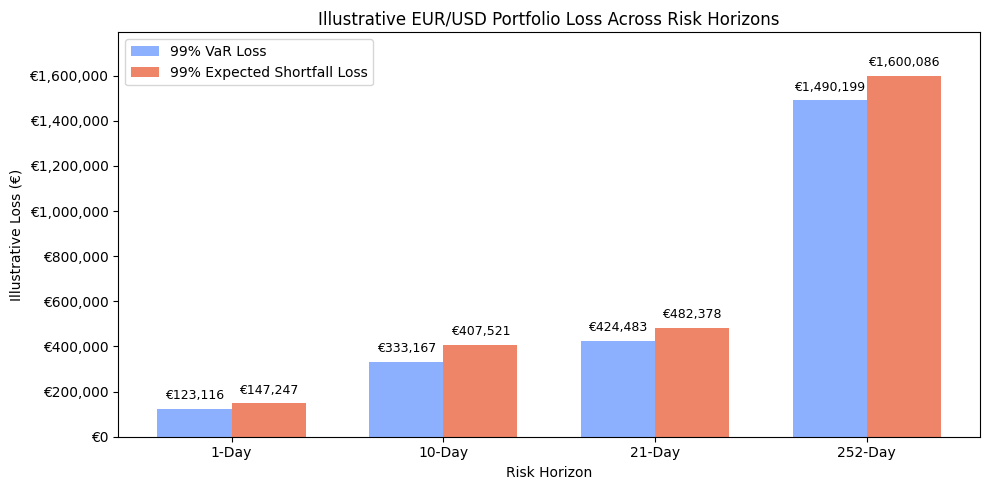

In [76]:
plt.figure(figsize=(10, 5))

x = np.arange(len(portfolio_loss_summary))
width = 0.35

var_bars = plt.bar(
    x - width / 2,
    portfolio_loss_summary["VaR Loss (€)"],
    width,
    label="99% VaR Loss",
    color=plt.cm.coolwarm(0.25)
)

es_bars = plt.bar(
    x + width / 2,
    portfolio_loss_summary["Expected Shortfall Loss (€)"],
    width,
    label="99% Expected Shortfall Loss",
    color=plt.cm.coolwarm(0.80)
)

# Add values above VaR bars
for bar in var_bars:
    height = bar.get_height()
    plt.annotate(
        f"€{height:,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Add values above ES bars
for bar in es_bars:
    height = bar.get_height()
    plt.annotate(
        f"€{height:,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("Illustrative EUR/USD Portfolio Loss Across Risk Horizons")
plt.xlabel("Risk Horizon")
plt.ylabel("Illustrative Loss (€)")
plt.xticks(x, portfolio_loss_summary.index)

plt.gca().yaxis.set_major_formatter(
    plt.matplotlib.ticker.StrMethodFormatter("€{x:,.0f}")
)

plt.legend()
plt.tight_layout()
plt.ylim(0, portfolio_loss_summary["Expected Shortfall Loss (€)"].max() * 1.12)
plt.show()

### Portfolio Loss Analysis — Key Findings

For the illustrative €10 million EUR/USD portfolio, the 99% Historical VaR and Expected Shortfall estimates are translated into hypothetical EUR losses across the selected risk horizons.

The estimated monetary losses increase as the risk horizon becomes longer, reflecting the larger cumulative return movements observed over longer historical periods.

Expected Shortfall produces a larger estimated loss than VaR at every horizon because it captures the average severity of observations beyond the VaR threshold.

The monetary figures are illustrative translations of percentage-based historical return risk applied to a hypothetical €10 million notional. They should not be interpreted as a full portfolio VaR calculation or as regulatory capital requirements.

The numerical values in the table and chart are generated from the current EUR/USD dataset and will update automatically when the notebook is rerun.

## Limitations

This case study is designed as an illustrative market risk analytics project rather than a production risk engine.

Key limitations include:

- The analysis uses a single EUR/USD exchange-rate series rather than a multi-asset portfolio with explicit positions and risk-factor sensitivities.
- Historical VaR and Expected Shortfall are dependent on the selected historical sample.
- Parametric and Monte Carlo estimates assume normally distributed returns.
- The Monte Carlo framework does not model volatility clustering, jumps, stochastic volatility, or other non-normal FX dynamics.
- The multi-horizon analysis uses observed historical multi-day returns and does not represent a full portfolio revaluation or regulatory capital calculation.
- The monetary portfolio-loss translations are simplified applications of percentage risk measures to hypothetical notionals.
- Market data is sourced from Yahoo Finance through `yfinance` and is intended for educational and portfolio-demonstration purposes.

These limitations should be considered when interpreting the results.